## 1. First of all Python must pre-installed on your computer, then install Pandas
## 2. Then install Pandas by any of the following commands:

In [ ]:
pip install pandas       #---on windows command prompt
!pip install pandas      #---within the jupyter notebook cells
conda install pandas     #---using anaconda on command prompts

In [ ]:
import pandas as pd
series = pd.Series([10,20,30,40,50,50,50,20,30,60])
strFruits=pd.Series([10,20,'Banana','Mango','Apple','Orange','Grapes'])

In [ ]:
print(strFruits.dtype)

In [ ]:
series

In [ ]:
series.index = ['One', 'Two', 'Three','Four', 'Five','Six','Seven','eight','nime','ten']
print(series.index)

In [ ]:
print(series)

In [ ]:
series.values 

In [ ]:
print("Is unique ?:", series.is_unique, "Series Dimensions:", series.ndim, "Series Shape:", series.shape,"Sereies Size:",series.size)

In [ ]:
print("Unorted Series with Sorting:",series.sort_values(ascending=False))  #without arg. It will be sorted by default

In [ ]:
print("Sorted Series:",series.sort_index)

In [ ]:
print("Sorted Series:",series.count())

In [ ]:
series.describe()                #fully applicable on numeric data values

In [ ]:
strFruits.describe()         #On strings behaves differently

In [ ]:
print("Min. Index:", series.idxmin(), "---Max. Index:", series.idxmax())

In [ ]:
print("----Number of Values:", series.value_counts())

In [ ]:
print("Values on Top:", series.head(3))

In [ ]:
print("Last Values:", series.tail(2))

### 'inplace' parameter, in Pandas objects used to modifies the original Series directly instead of returning a new one, i.e. without reassign the result back to the variable. 
### Here we applying inplace=True using your exact Series for both sort_values() and sort_index().

In [ ]:
series.sort_values(inplace=True)
print(series)

### Because the previous step scrambled the index order, you can use sort_index(inplace=True) to put the Series back into its original index sequence.

In [ ]:
series.sort_index(inplace=True)
print(series)

### In addition to above, other Pandas series methods, for example data filtering are:
#### unique(): Returns an array of unique values in the order they appear.
#### nunique(): Returns the integer count of unique values.
#### isin(list): Checks if elements are contained within a passed list, returning booleans.
#### between(left, right): Filters elements that fall inside a given boundary

### Pandas DataFrames

#### Reading a .csv (comma separated values) data file

In [ ]:
csvfile=pd.read_csv('D:/2CE/students.csv')

In [ ]:
print(csvfile)

In [ ]:
print(csvfile.columns)

In [ ]:
df=pd.DataFrame(csvfile)

In [ ]:
print(df)

In [ ]:
print(df[['Sname','Course','Percent']])

### DataFrame Methods
####  how to use the sort_values(), sort_index(), astype(), loc[], and iloc[] methods on a Pandas DataFrame?


In [ ]:
print(df.sort_values(df))

In [ ]:
print(df.sort_index())

In [ ]:
#df = df.astype({'Column_Name1': 'int32', 'Column_Name2': 'float64'})

In [ ]:
df['Percent'] = df['Percent'].astype(int)

In [ ]:
print(df['Percent'])

In [ ]:
print(df.loc[0:2])      # Select data by index, or Label/column names

In [ ]:
print(df.loc[1, ['Sname','Course']])

In [ ]:
print(df.loc[2:5, ['Sname', 'Quali']])

In [ ]:
print(df.iloc[0])          # Select data by integer value location iloc[]

In [ ]:
print(df.iloc[0, 2])

In [ ]:
print(df.iloc[0:2, 0:3])

### Delete rows and columns from a dataFrame

In [ ]:
newDF = df[['AppNo','Sname','Quali','Percent']]

In [ ]:
print(newDF)

In [ ]:
df_clean = df.drop(columns='ColumnName')
df_clean = df.drop(columns=['Column1', 'Column2'])

In [ ]:
colDel=newDF.drop(columns=['Quali','Sname'])
print(colDel)

In [ ]:
# axis=1 tells Pandas to look at column labels instead of row labels
df_clean = newDF.drop(['Sname', 'Quali'], axis=1)
print(df_clean)

In [ ]:
df

In [ ]:
df_clean = newDF.drop(index=4)  # Delete exact indexed row using index, axis=0
print(df_clean)

In [ ]:
df_clean = newDF.drop(newDF.index[0:3])   # Delete row using index, axis=0, multiple rows at once by slicing
print(df_clean)

In [ ]:
df.drop(columns='Course', inplace=True)       # Permanently delete the 'Course' column from the original df
df.drop(index=3, inplace=True)            # Permanently delete row 3 from the original df 

### Merging and joining dataFrames

#### We can combine two or more DataFrames using merge() method of Pandas (for SQL-like joins based on columns) and join() (for combining data based on index labels).

#### To combine Pandas DataFrames, we primarily use pd.merge() method for database-style joins (on columns) or df.join() for joining on index keys. Here is a quick breakdown of how to use both methods.

### $\textbf{\color{Maroon}The {\color{blue}'how'} parameter (Join Types):}$
#### $\textbf{\color{red}how='inner' (Default):}$ Keeps only the rows where the join key matches in both DataFrames.
#### $\textbf{\color{red}how='left':}$ Keeps all rows from the left DataFrame, filling missing values from the right with NaN.
#### $\textbf{\color{red}how='right':}$ Keeps all rows from the right DataFrame, filling missing values from the left with NaN.
#### $\textbf{\color{red}how='outer':}$ Keeps all rows from both DataFrames, filling missing values with NaN everywhere.

#### Use $\textbf{\color{red}df.join()}$ when you want to combine DataFrames based on their index labels instead of column values. 
#### By default, $\textbf{\color{red}df.join()}$ performs a left join.

In [ ]:
df_a = df[['AppNo', 'Sname', 'Quali']]        #Merging -- since both DataFrames share the AppNo column, 
                                            #you link them together using the on parameter:
df_b = df[['AppNo', 'Percent']]

In [ ]:
print(df_a)

In [ ]:
print(df_b)

In [ ]:
merged_df = pd.merge(df_a, df_b, on='AppNo', how='inner')
print(merged_df)

### $\textbf{\color{Maroon}'join':}$
#### If you move your key column (AppNo) into the DataFrame index, you can use df.join(), 
#### which is cleaner and faster for index-to-index matching.

In [ ]:
df1 = df[['AppNo', 'Sname', 'Quali']].set_index('AppNo')      #splitting the dataset
df2 = df[['AppNo', 'Percent']].set_index('AppNo')

In [ ]:
joined_df = df1.join(df2)          #join / combine two dataFrames using join()
print(joined_df)

#### If you divide your DataFrame horizontally (e.g., first 5 students in one table, last 4 students in another), 
#### then there is no matching criteria to join, but can be combined in on using pd.concat() as --->

In [ ]:
topRecords = df.iloc[:3]            # First 5 rows
print(topRecords)

In [ ]:
botRecords = df.iloc[7:]               # Remaining rows
print(botRecords)

In [ ]:
concatDF = pd.concat([topRecords, botRecords], axis=0)
print(concatDF)

### $\textbf{\color{Magenta} Broadcasting:}$
#### In Pandas, broadcasting refers to how mathematical and logical operations are handled between objects of different dimensions (such as a DataFrame and a Series, or a DataFrame and a scalar value).
#### Pandas automatically $\textbf{\color{Red}stretches or replicates}$ the smaller object across the rows or columns of the larger DataFrame so that their shapes match up for element-wise calculations.

In [ ]:
print(df)

In [ ]:
df['Quali'] = '10+3' 
print(df['Quali'])

In [ ]:
dfA=pd.Series(df['Percent'])

In [ ]:
dfA['Percent'] = df['Percent'] + 2.0  # To add 2.0 in each cell 'Percent' of every row / element-wise

In [ ]:
print(df['Percent'], dfA['Percent'])

In [ ]:
df_marks = pd.DataFrame({
    'PyTest_1': [76.80, 85.65, 79.85],
    'PyTest_2': [80.00, 88.00, 82.50]
}, index=['Varun', 'Sushil', 'Kamal'])

deductions = pd.Series([1.5, 2.0, 0.5], index=['Varun', 'Sushil', 'Kamal']) # Deductions unique to each row
final_df = df_marks.sub(deductions, axis=0)           # Broadcast across columns by row index (axis=0)
print(final_df)

### $\textbf{\color{Green} Handling Data Values:- missing values, duplicates, and categorical values:}$

#### $\textbf{\color{blue}Loading data:}$ The first step in data preprocessing is to load the data into pandas. You can use pandas' read_csv() function to read CSV files or read_excel() function to read Excel files.
#### $\textbf{\color{blue}Handling missing values:}$ Missing values can cause issues in data analysis. Pandas provides functions like isna(), fillna(), and dropna() to handle missing values.
#### $\textbf{\color{blue}Removing duplicates:}$ Duplicates in the dataset can skew the analysis results. The drop_duplicates() function in pandas can be used to remove duplicates.
#### $\textbf{\color{blue} Handling categorical variables:}$ Categorical variables are non-numeric data types. Pandas provides functions like get_dummies() and LabelEncoder() to handle categorical variables.
#### $\textbf{\color{Maroon} Handling outliers:}$ Outliers can have a significant impact on analysis results. Pandas provides functions like describe() and quantile() to identify outliers and handle them.
#### $\textbf{\color{Maroon} Normalizing data:}$ Normalizing data involves scaling data to a standard range. The StandardScaler() function in pandas can be used to normalize data.
#### $\textbf{\color{Maroon} Aggregating data:}$ Aggregating data involves grouping data by certain attributes and performing calculations on the groups. Pandas provides the groupby() function to perform data aggregation.
#### $\textbf{\color{Maroon} Merging data:}$ Merging data involves combining multiple datasets into one. Pandas provides the merge() function to merge datasets.
#### $\textbf{\color{Maroon} Reshaping data:}$ Reshaping data involves changing the structure of data. Pandas provides functions like pivot() and melt() to reshape data.
####  By performing these common steps in data preprocessing with pandas, data analysts can get cleaner and more organized data that can be used for further numerical and quantitative analysis. 

### $\textbf{\color{Cyan}Why Handling Missing Categorical Data is Important:}$
#### Categorical variables represent distinct categories or labels rather than numerical values. 

#### For examples gender, city, pincode, basic_pay, gross_salary, income_tax_rate, quantity, and SGST, CGST, etc. 
#### Missing values in these variables can disrupt machine learning models, causing poor predictions and inefficiencies. Therefore, handling missing categorical data is critical to building reliable machine learning models.

#### Machine learning algorithms are not inherently designed to handle missing values, and most require complete datasets to function correctly. Effective imputation techniques can ensure that the absence of data doesn’t compromise your model’s accuracy.

### $\textbf{\color{Red} Types of Missing Values:}$

#### $\textbf{\color{purple }Missing Completely At Random (MCAR)}$
MCAR occurs when the probability of data being missing is uniform across all observations. There is no relationship between the missingness of data and any other observed or unobserved data within the dataset. 

Example: For example some returned / or not returned overdue book values are missing / not recorded in the dataset, and are missing due to human error.

#### $\textbf{\color{purple }Missing At Random (MAR)}$
MAR data occurs when the probability of data being missing depends only on the observed data and not on the missing data itself. In other words, the missingness can be explained by variables for which you have complete information. There is a pattern in the missing values, but this pattern can be explained by other observed variables.

Example: In a survey, ‘Age’ values might be missing for those who did not disclose their ‘Gender’. Here, the missingness of ‘Age’ depends on ‘Gender’, but the missing ‘Age’ values are random among those who did not disclose their ‘Gender’.

#### $\textbf{\color{purple}Missing Not At Random (MNAR)}$
MNAR occurs when the missingness of data is related to the unobserved data itself, which is not included in the dataset. This type of missing data has a specific pattern that cannot be explained by observed variables.

Example: For library books, people with more overdue books might be less likely to respond to return. Thus, the number of overdue books is missing and depends on the number of books overdue.

Understanding the type of missing data is crucial because it determines the appropriate strategy for handling missing values and ensuring the integrity of statistical analyses.

In [ ]:
import pandas as pd
import numpy as np
nba=pd.read_csv('D:/2CE/nba2.csv')

In [ ]:
nbadf=pd.DataFrame(nba)

In [ ]:
aa=nbadf.head(20)

In [ ]:
print(aa[['Name','Salary']])

In [ ]:
print(aa.dropna())

In [ ]:
data = {
    'A': [10, 20, np.nan, 40, 50, np.nan, np.nan,80,np.nan,100],
    'B': [np.nan, 20, 30, np.nan, np.nan, 60, np.nan, 80, 90, np.nan],
    'C': [100, 200, 300, np.nan, 500, np.nan, np.nan, 800, np.nan, np.nan],
    'D': [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]
}
df = pd.DataFrame(data)

In [ ]:
df

In [ ]:
styled_df = df.style.highlight_null(color='magenta')
styled_df

In [ ]:
df['C'] = df['C'].replace(0, np.nan)
df

In [ ]:
df['C'] = df['C'].fillna(df['C'].mode()[0])         # fill missing missing values with mode
df

In [ ]:
df.isna()                 #return True if NaN exists, False otherwise 

In [ ]:
df['B'] = df['B'].replace(0, np.nan)
df

In [ ]:
df['B']=df['B'].fillna(value=df['B'].median())      # fill missing missing values with median
df

In [ ]:
df['A']=df['A'].fillna(value=df['A'].mean())      # fill missing missing values with mean
df

In [ ]:
df

### $\textbf{\color{Green} Missing Values Data Handling Techniques:}$

In [ ]:
cleaned=df.dropna()               # all the records/rows having NaN in any column to be deleted, may use inplace=True

In [ ]:
cleaned

In [ ]:
df['A'].fillna(value=df['A'].mean())        # fill missing values with mean of a column values
df

In [ ]:
df.fillna(value=0, inplace=True)        # replace missing values with 0
df

In [ ]:
df['B'].fillna(value=df['B'].median())      # fill missing missing values with median
df

In [ ]:
df.style.highlight_max()

In [ ]:
df.style.highlight_min()

In [ ]:
D1 = {
    'A': [100, 200, np.nan, 400, 500],
    'B': [np.nan, 200, 300, 400, 500],
    'C': [10, 20, 30, np.nan, 50],
    'D': [10, 20, 30, 40, 50]
}
df1 = pd.DataFrame(D1)

D2 = {
    'A': [100, 200, 300, 400, 500],
    'B': [100, 200, 300, 400, 500],
    'C': [10, 20, 30, 40, 50],
    'D': [10, 20, 30, 40, 50]
}

In [ ]:
D1

In [ ]:
D2

In [ ]:
df2 = pd.DataFrame(D2)
df1.fillna(df2, inplace=True)         # fill missing values from second dataFrame df2
print(df1)

In [ ]:
df.style.format(precision=2).background_gradient().hide(axis='index').to_excel(
    '2ce_styled.xlsx',
    engine='openpyxl'
)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
plt.close("all")

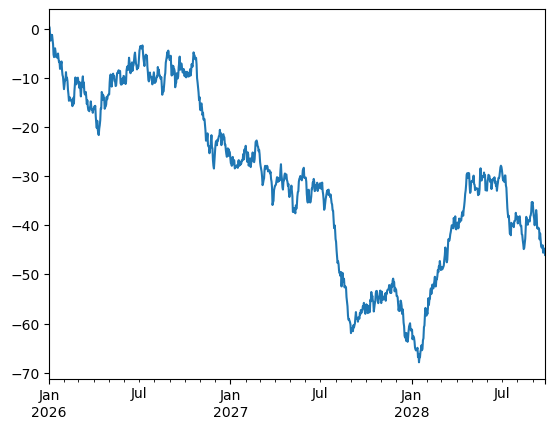

In [2]:
np.random.seed(123456)
ts = pd.Series(np.random.randn(1000), index=pd.date_range("1/1/2026", periods=1000))
ts = ts.cumsum()
ts.plot();            #basic plot function to draw a figure with data

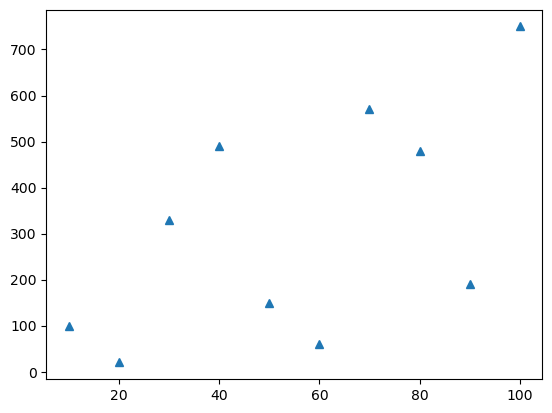

In [4]:
x=[10,20,30,40,50,60,70,80,90,100]
y=[100,20,330,490,150,60,570,480,190,750]
plt.plot(x,y, '^')

<Figure size 640x480 with 0 Axes>

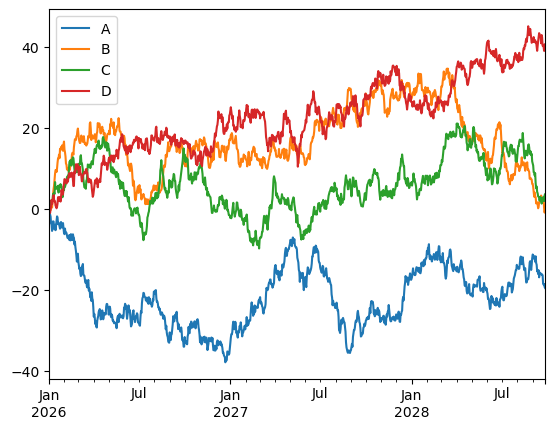

In [5]:
df = pd.DataFrame(np.random.randn(1000, 4), index=ts.index, columns=list("ABCD")) #Plot all of the columns with labels
df = df.cumsum()
plt.figure();
df.plot();

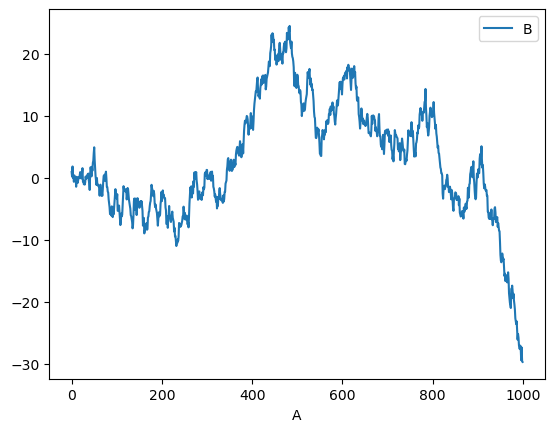

In [6]:
df3 = pd.DataFrame(np.random.randn(1000, 2), columns=["B", "C"]).cumsum()        #column versus another using the x and y in plot()
df3["A"] = pd.Series(list(range(len(df))))
df3.plot(x="A", y="B");

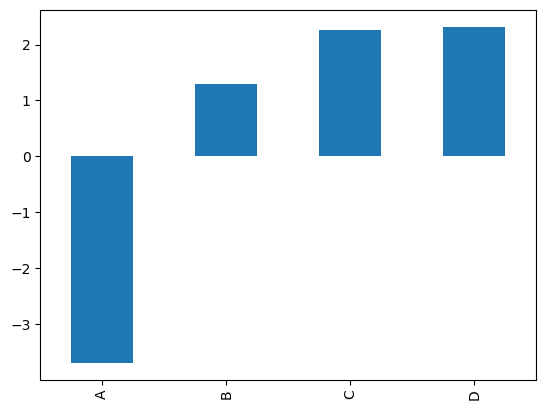

In [7]:
plt.figure();
df.iloc[5].plot(kind="bar");

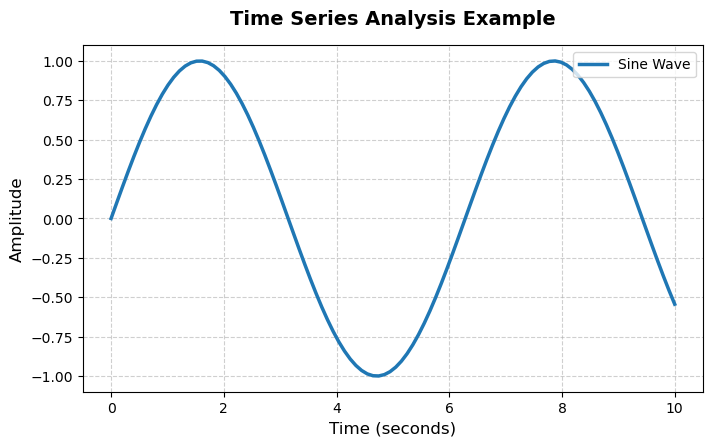

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Generate sample time-series data
x = np.linspace(0, 10, 100)
y = np.sin(x)

# Create figure and axis objects
fig, ax = plt.subplots(figsize=(8, 4.5))

# Plot data with custom styling
ax.plot(x, y, color='#1f77b4', linewidth=2.5, linestyle='-', label='Sine Wave')

# Customize labels, title, and grid
ax.set_title('Time Series Analysis Example', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Time (seconds)', fontsize=12)
ax.set_ylabel('Amplitude', fontsize=12)
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(loc='upper right')

# Display the plot
plt.show()

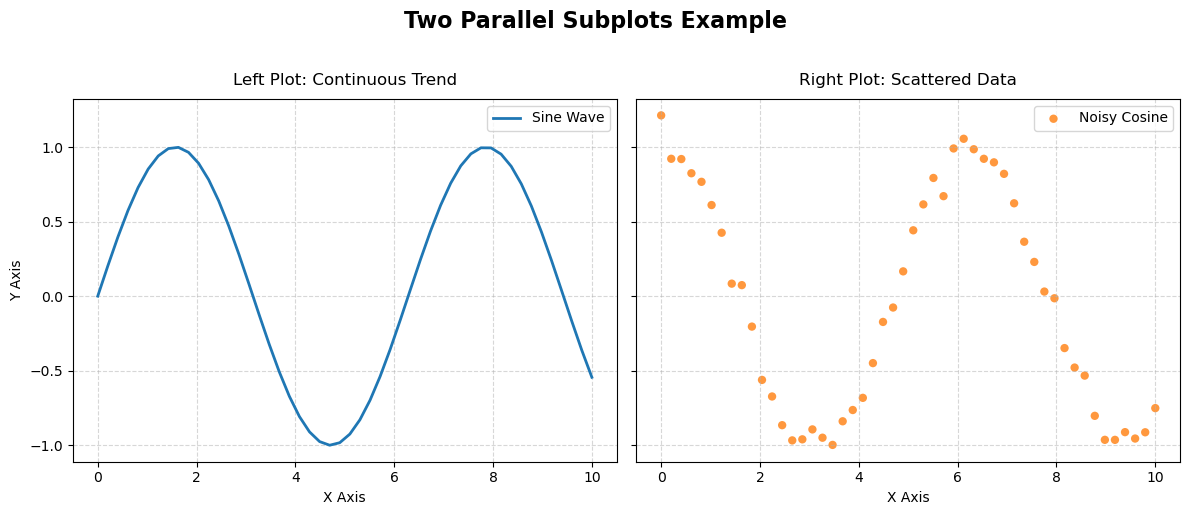

In [2]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Generate sample data
x = np.linspace(0, 10, 50)
y1 = np.sin(x)
y2 = np.cos(x) + np.random.normal(0, 0.1, 50)  # Added noise for the scatter plot

# 2. Create a figure with 1 row and 2 columns
# sharey=True ensures both plots use the exact same vertical scale
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(12, 5), sharey=True)

# 3. Customize the Left Plot (Line Chart)
ax1.plot(x, y1, color='#1f77b4', linewidth=2, label='Sine Wave')
ax1.set_title('Left Plot: Continuous Trend', fontsize=12, pad=10)
ax1.set_xlabel('X Axis', fontsize=10)
ax1.set_ylabel('Y Axis', fontsize=10)  # Shared Y label
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend()

# 4. Customize the Right Plot (Scatter Plot)
ax2.scatter(x, y2, color='#ff7f0e', alpha=0.8, edgecolors='none', label='Noisy Cosine')
ax2.set_title('Right Plot: Scattered Data', fontsize=12, pad=10)
ax2.set_xlabel('X Axis', fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend()

# 5. Add a global figure title and optimize layout spacing
fig.suptitle('Two Parallel Subplots Example', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()

# 6. Render the dashboard
plt.show()

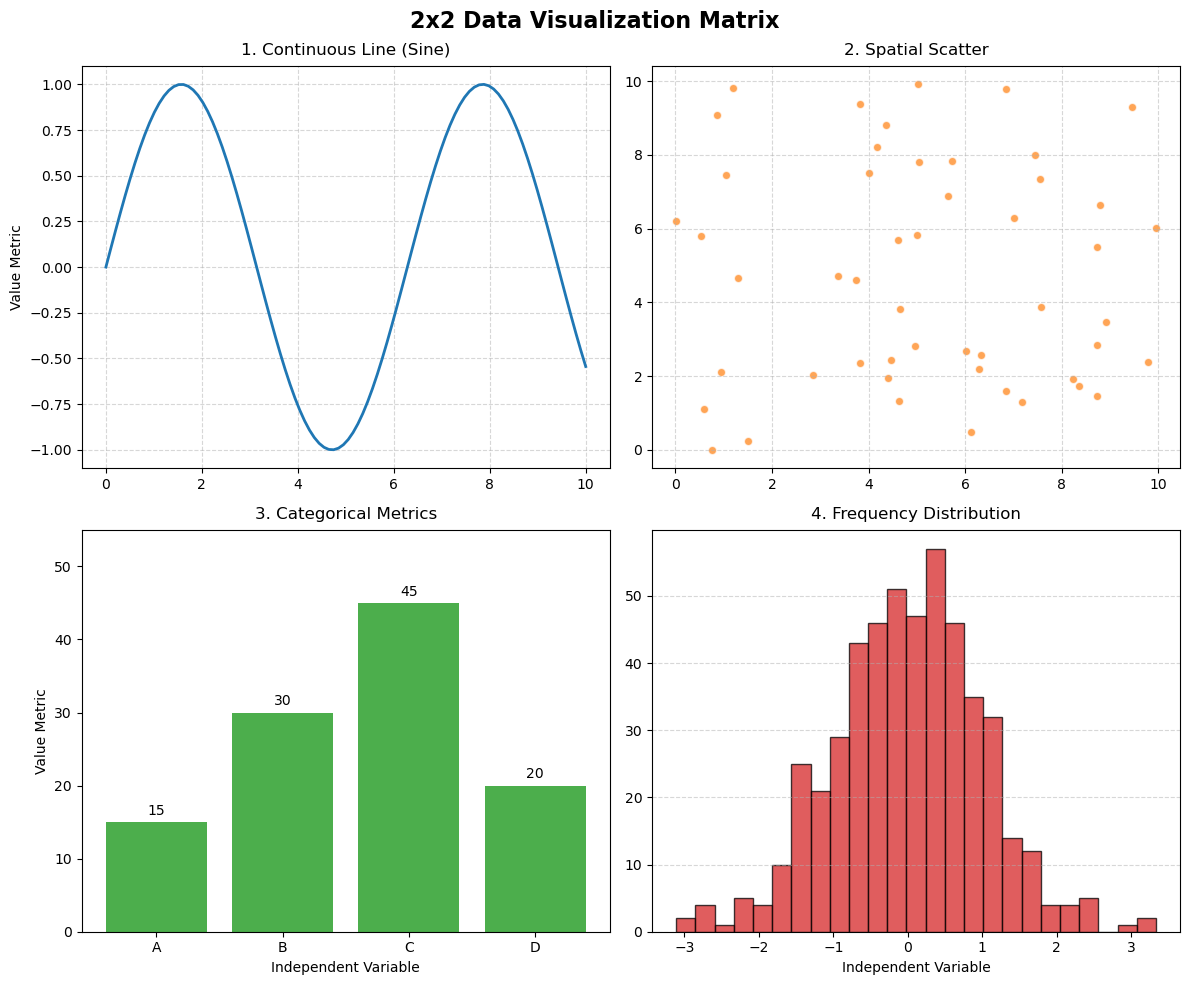

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Generate diverse sample datasets
x = np.linspace(0, 10, 100)
categorical_labels = ['A', 'B', 'C', 'D']
categorical_values = [15, 30, 45, 20]
normal_distribution = np.random.normal(0, 1, 500)

# 2. Initialize a 2x2 subplot layout
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 10))

# Deconstruct the 2D array for cleaner script styling
# axes[0, 0] -> Top-Left | axes[0, 1] -> Top-Right
# axes[1, 0] -> Bottom-Left | axes[1, 1] -> Bottom-Right
(ax1, ax2), (ax3, ax4) = axes

# ---------------------------------------------------------
# Subplot 1: Line Plot (Top-Left)
# ---------------------------------------------------------
ax1.plot(x, np.sin(x), color='#1f77b4', linewidth=2)
ax1.set_title('1. Continuous Line (Sine)', fontsize=12, pad=8)
ax1.grid(True, linestyle='--', alpha=0.5)

# ---------------------------------------------------------
# Subplot 2: Scatter Plot (Top-Right)
# ---------------------------------------------------------
# Generating random coordinate clusters
random_x = np.random.rand(50) * 10
random_y = np.random.rand(50) * 10
ax2.scatter(random_x, random_y, color='#ff7f0e', alpha=0.7, edgecolors='w')
ax2.set_title('2. Spatial Scatter', fontsize=12, pad=8)
ax2.grid(True, linestyle='--', alpha=0.5)

# ---------------------------------------------------------
# Subplot 3: Bar Chart (Bottom-Left)
# ---------------------------------------------------------
bars = ax3.bar(categorical_labels, categorical_values, color='#2ca02c', alpha=0.85)
ax3.bar_label(bars, padding=3)  # Automatically append values above bars
ax3.set_title('3. Categorical Metrics', fontsize=12, pad=8)
ax3.set_ylim(0, 55)  # Make room for the bar labels

# ---------------------------------------------------------
# Subplot 4: Histogram (Bottom-Right)
# ---------------------------------------------------------
ax4.hist(normal_distribution, bins=25, color='#d62728', alpha=0.75, edgecolor='black')
ax4.set_title('4. Frequency Distribution', fontsize=12, pad=8)
ax4.grid(axis='y', linestyle='--', alpha=0.5)

# ---------------------------------------------------------
# Global Layout Adjustments
# ---------------------------------------------------------
# Apply standard labels across exterior edges if needed
for ax in [ax1, ax3]:
    ax.set_ylabel('Value Metric', fontsize=10)
for ax in [ax3, ax4]:
    ax.set_xlabel('Independent Variable', fontsize=10)

fig.suptitle('2x2 Data Visualization Matrix', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()

# Render visual canvas
plt.show()

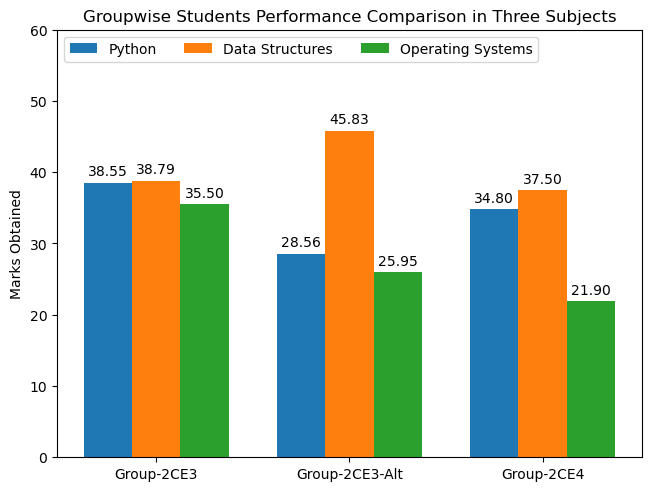

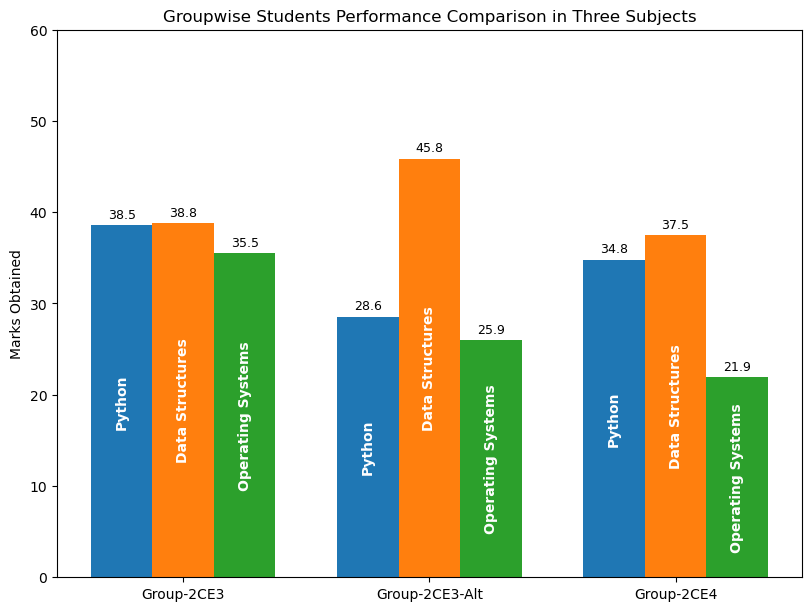

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Added quotes to define strings properly
groups = ('Group-2CE3', 'Group-2CE3-Alt', 'Group-2CE4') 
subjects = {
    'Python': (38.55, 28.56, 34.80),
    'Data Structures': (38.79, 45.83, 37.50),
    'Operating Systems': (35.50, 25.95, 21.90),
}

x = np.arange(len(groups))  # The label locations
width = 0.25  # The width of the bars
multiplier = 0

fig, ax = plt.subplots(layout='constrained')

# Iterate through the dictionary to plot each subject's bars with an offset
for attribute, measurement in subjects.items():
    offset = width * multiplier
    rects = ax.bar(x + offset, measurement, width, label=attribute)
    ax.bar_label(rects, padding=3, fmt='%.2f')
    multiplier += 1

# Add text for labels, title, and custom x-axis tick labels
ax.set_ylabel('Marks Obtained')
ax.set_title('Groupwise Students Performance Comparison in Three Subjects')

# Center the tick labels relative to the groups of bars
ax.set_xticks(x + width, groups)
ax.legend(loc='upper left', ncols=3)

# Adjusted the Y-limit to fit the data points (max mark is ~46)
ax.set_ylim(0, 60)

plt.show()


# Second version to show legends within the bars
# ==============================================

groups = ['Group-2CE3', 'Group-2CE3-Alt', 'Group-2CE4'] 
subjects = {
    'Python': [38.55, 28.56, 34.80],
    'Data Structures': [38.79, 45.83, 37.50],
    'Operating Systems': [35.50, 25.95, 21.90],
}

x = np.arange(len(groups))  
width = 0.25  
multiplier = 0

fig, ax = plt.subplots(layout='constrained', figsize=(8, 6))

for attribute, measurement in subjects.items():
    offset = width * multiplier
    rects = ax.bar(x + offset, measurement, width)
    
    # Text inside the bars: Displays the Key (Subject) vertically
    ax.bar_label(rects, labels=[attribute]*len(measurement), 
                 label_type='center', rotation=90, color='white', fontweight='bold')
    
    # Text on top of the bars: Displays the numeric Marks
    ax.bar_label(rects, padding=3, fmt='%.1f', fontsize=9)
    
    multiplier += 1

ax.set_ylabel('Marks Obtained')
ax.set_title('Groupwise Students Performance Comparison in Three Subjects')
ax.set_xticks(x + width, groups)
ax.set_ylim(0, 60)

plt.show()